# 02: Follow-up experiments

| Section | Output | Manuscript |
|---|---|---|
| 2 | batteries and sweeps in each partition | Section 2.1 |
| 3 | seed-42 single run, ROC | Table 3, Figure 4 |
| 4 | ten seeds, validation-Youden threshold for every model, paired t-tests, sweep bootstrap CIs | Table 5, Section 4.1 |
| 5 | ablation A1, matched and unmatched | Table 6, Section 4.2 |
| 6 | physical-consistency metric | Section 4.5 |
| 7 | validation-tuned RF, GB, SVM, logistic regression | Table 5 |
| 8 | λ = 0 validation row | Table 7 |
| 9 | 50% and 70% SoC cutoffs | Section 4.6 |
| 10 | Randles-CPE-Warburg fits per sweep | Figure 8C, Section 4.5 |
| 11 | package versions | Section 3.4 |
| last two cells | exact-ROC single run (Table 3, 4) and validation λ sweep | Tables 3, 4, 7, Figure 5B |

**Run:** place `impedance.csv` and `frequencies.csv` in `data/` (or upload them when prompted in Colab), then Runtime → Run all. Saved outputs are those reported in the manuscript.

In [ ]:
RUN = {
    "splits": True,          # section 2
    "single_run": True,      # section 3
    "multiseed": True,       # section 4  (needed by 6 and 7)
    "ablation_A1": True,     # section 5
    "consistency": True,     # section 6
    "strong_baselines": True,# section 7
    "lambda0": True,         # section 8
    "cutoffs": True,         # section 9
    "rct_fit": True,         # section 10
}
N_SEEDS = 10                 # seeds 0-9, as in Tables 5 and 6
N_SEEDS_LAMBDA = 8           # seeds 0-7, as in Table 7
N_SEEDS_CUTOFF = 10
N_BOOT = 2000

## 0. Setup and data

In [ ]:
import os, json, time, random, warnings, zipfile, platform
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.optim as optim
import sklearn
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, accuracy_score
from scipy import stats
from scipy.optimize import least_squares
import scipy
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

QUICK = os.environ.get("QUICK") == "1"     # only used for a fast smoke test
MAX_EPOCHS = 3 if QUICK else 300
if QUICK:
    N_SEEDS, N_SEEDS_LAMBDA, N_SEEDS_CUTOFF, N_BOOT = 2, 2, 2, 50

os.makedirs("results", exist_ok=True)
T0 = time.time()
def elapsed(): return f"{(time.time()-T0)/60:.1f} min"
def save(name, obj):
    with open(f"results/{name}.json", "w") as f:
        json.dump(obj, f, indent=2, default=float)
    print(f"saved results/{name}.json ({elapsed()})")

IMP_PATH, FREQ_PATH = "data/impedance.csv", "data/frequencies.csv"
if not (os.path.exists(IMP_PATH) and os.path.exists(FREQ_PATH)):
    os.makedirs("data", exist_ok=True)
    from google.colab import files
    print("Please upload impedance.csv and frequencies.csv:")
    up = files.upload()
    for fn in up:
        with open("data/" + fn, "wb") as f:
            f.write(up[fn])
print("data ready")

Please upload impedance.csv and frequencies.csv:


Saving frequencies (2).csv to frequencies (2).csv
Saving impedance (2).csv to impedance (2).csv
data ready


## 1. Preprocessing, sweep-grouped chronological split, model
Identical to the main Experiments / AUC notebooks. `make_windows` additionally
keeps the SoC level and battery of every window, and single-point (un-windowed)
features are built for the A1 ablation.

In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

impedance = pd.read_csv(IMP_PATH)
frequencies = pd.read_csv(FREQ_PATH)
df = impedance.merge(frequencies, on="FREQUENCY_ID", how="left")
df["SWEEP_ID"] = df["BATTERY_ID"].astype(str) + "_" + df["MEASURE_ID"].astype(str) + "_" + df["SOC"].astype(str)

def parse_complex(s):
    if pd.isna(s): return np.nan
    s = str(s).replace(" ", "").replace("(", "").replace(")", "")
    try: return complex(s)
    except ValueError: return np.nan

df["Z_complex"] = df["IMPEDANCE_VALUE"].apply(parse_complex)
df["Re_Z"] = df["Z_complex"].apply(lambda z: z.real)
df["Im_Z"] = df["Z_complex"].apply(lambda z: z.imag)
df["abs_Z"] = df["Z_complex"].apply(lambda z: abs(z))
df = df.dropna(subset=["Re_Z", "Im_Z", "abs_Z", "SOC"]).reset_index(drop=True)
freq_col = "FREQUENCY_VALUE"
df["log10_f"] = np.log10(df[freq_col].astype(float))
df["phi"] = np.arctan2(df["Im_Z"], df["Re_Z"])
FEATS = ["log10_f", "Re_Z", "Im_Z", "abs_Z", "phi"]
print("rows:", len(df), "| sweeps:", df["SWEEP_ID"].nunique())

Xw, zw, socw, sidw = [], [], [], []          # windowed (3-point) samples
Xp, zp, socp, sidp, centre = [], [], [], [], []   # single-point samples (all 14 points)
for key, g in df.groupby("SWEEP_ID", sort=False):
    g = g.sort_values(freq_col).reset_index(drop=True)
    n = len(g)
    for i in range(n):
        Xp.append(g.loc[i, FEATS].values.astype(float)); zp.append(g.loc[i, "abs_Z"])
        socp.append(g.loc[i, "SOC"]); sidp.append(key); centre.append(0 < i < n - 1)
    for i in range(1, n - 1):
        Xw.append(np.concatenate([g.loc[i-1, FEATS].values, g.loc[i, FEATS].values, g.loc[i+1, FEATS].values]).astype(float))
        zw.append(g.loc[i, "abs_Z"]); socw.append(g.loc[i, "SOC"]); sidw.append(key)
Xw, zw, socw, sidw = map(np.array, (Xw, zw, socw, sidw))
Xp, zp, socp, sidp, centre = map(np.array, (Xp, zp, socp, sidp, centre))
print(f"windows={len(Xw)} (expect 2,880) | single points={len(Xp)} (expect 3,360)")

def group_boundaries(sids):
    b = [0]
    for i in range(1, len(sids)):
        if sids[i] != sids[i-1]: b.append(i)
    b.append(len(sids)); return b
bounds = group_boundaries(sidw)
n = len(Xw)
n_train = min(bounds, key=lambda b: abs(b - 0.70 * n))
n_trainval = min([b for b in bounds if b > n_train], key=lambda b: abs(b - 0.85 * n))
for cut in (n_train, n_trainval):
    assert sidw[cut-1] != sidw[cut], "cut splits a sweep"
part_w = np.array(["train"] * n_train + ["val"] * (n_trainval - n_train) + ["test"] * (n - n_trainval))
sweep_part = dict(zip(sidw, part_w))                 # every sweep -> its partition
part_p = np.array([sweep_part[s] for s in sidp])     # same sweeps for single points
print(f"split: train={np.sum(part_w=='train')}, val={np.sum(part_w=='val')}, test={np.sum(part_w=='test')}")

def labels(soc, cutoff=60): return (soc >= cutoff).astype(int)

def make_sets(X, z, part, mask=None):
    """standardise X and min-max scale z with TRAIN statistics only (z clipped to [0,1])."""
    if mask is None: mask = np.ones(len(X), bool)
    tr, va, te = [(part == p) & mask for p in ("train", "val", "test")]
    sc = StandardScaler().fit(X[tr])
    zmin, zmax = z[tr].min(), z[tr].max()
    zn = np.clip((z - zmin) / (zmax - zmin + 1e-12), 0, 1)
    return dict(tr=tr, va=va, te=te, Xs=sc.transform(X), zn=zn)

W = make_sets(Xw, zw, part_w)
y60 = labels(socw)

class PGNN(nn.Module):
    def __init__(self, in_dim=15):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 128), nn.Tanh(), nn.Dropout(0.2),
                                 nn.Linear(128, 128), nn.Tanh(), nn.Dropout(0.2),
                                 nn.Linear(128, 64), nn.Tanh(), nn.Linear(64, 2))
    def forward(self, x): return self.net(x)

def physics_loss(p1, z_norm):
    return torch.mean(p1 * z_norm * (z_norm > 0.5).float())

def train_pgnn(Xtr, ytr, ztr, Xva, yva, lam=1.0, seed=0, lr=5e-4, patience=25, batch=64):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    Xt = torch.tensor(Xtr, dtype=torch.float32); yt = torch.tensor(ytr, dtype=torch.long)
    zt = torch.tensor(ztr, dtype=torch.float32)
    Xv = torch.tensor(Xva, dtype=torch.float32); yv = torch.tensor(yva, dtype=torch.long)
    model = PGNN(Xtr.shape[1]); ce = nn.CrossEntropyLoss()
    opt = optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.999), weight_decay=1e-4)
    sched = optim.lr_scheduler.StepLR(opt, step_size=50, gamma=0.5)
    best, best_state, bad = float("inf"), None, 0
    for epoch in range(MAX_EPOCHS):
        model.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch):
            idx = perm[i:i+batch]
            opt.zero_grad(); logits = model(Xt[idx]); p = torch.softmax(logits, 1)
            loss = ce(logits, yt[idx]) + lam * physics_loss(p[:, 1], zt[idx])
            loss.backward(); opt.step()
        sched.step(); model.eval()
        with torch.no_grad(): vl = ce(model(Xv), yv).item()
        if vl < best - 1e-6:
            best, best_state, bad = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model

@torch.no_grad()
def proba(model, X):
    return torch.softmax(model(torch.tensor(X, dtype=torch.float32)), 1)[:, 1].numpy()

GRID = np.linspace(0, 1, 500)          # 500 candidate thresholds (Section 3.2)
def youden(y, p):
    pos, neg = y == 1, y == 0
    j = [((p >= t) & pos).sum() / pos.sum() - ((p >= t) & neg).sum() / neg.sum() for t in GRID]
    return float(GRID[int(np.argmax(j))])

def metrics(y, p, tau):
    yhat = (p >= tau).astype(int)
    return dict(acc=float(accuracy_score(y, yhat)), f1=float(f1_score(y, yhat, average="macro")),
                auc=float(roc_auc_score(y, p)), tau=float(tau))

def run_pinn(S, y, lam=1.0, seed=0):
    m = train_pgnn(S["Xs"][S["tr"]], y[S["tr"]], S["zn"][S["tr"]], S["Xs"][S["va"]], y[S["va"]], lam=lam, seed=seed)
    return proba(m, S["Xs"][S["va"]]), proba(m, S["Xs"][S["te"]])

def run_sklearn(model, S, y):
    model.fit(S["Xs"][S["tr"]], y[S["tr"]])
    return model.predict_proba(S["Xs"][S["va"]])[:, 1], model.predict_proba(S["Xs"][S["te"]])[:, 1]

def evaluate(S, y, pv, pt):
    tau = youden(y[S["va"]], pv)
    out = {"test": metrics(y[S["te"]], pt, tau), "test_tau05": metrics(y[S["te"]], pt, 0.5),
           "val": metrics(y[S["va"]], pv, tau)}
    return out

def msd(a): a = np.asarray(a, float); return [float(a.mean()), float(a.std(ddof=1)) if len(a) > 1 else 0.0]
def paired(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = a - b
    if np.allclose(d, d[0]) or len(d) < 2: return dict(delta=float(d.mean()), p=None)
    return dict(delta=float(d.mean()), p=float(stats.ttest_rel(a, b).pvalue))
print("setup done", elapsed())

rows: 3360 | sweeps: 240
windows=2880 (expect 2,880) | single points=3360 (expect 3,360)
split: train=2016, val=432, test=432
setup done 0.5 min


## 2. Which batteries and sweeps fall in each split

In [ ]:
if RUN["splits"]:
    bat = np.array([s.split("_")[0] for s in sidw])
    split_info = {}
    for p in ("train", "val", "test"):
        m = part_w == p
        split_info[p] = dict(
            n_windows=int(m.sum()), n_sweeps=int(len(set(sidw[m]))),
            windows_per_battery={str(k): int(v) for k, v in pd.Series(bat[m]).value_counts().sort_index().items()},
            soc_levels=sorted(int(x) for x in set(socw[m])),
            n_low=int((y60[m] == 0).sum()), n_high=int((y60[m] == 1).sum()))
        print(p, split_info[p])
    # is any battery present in more than one partition? any session?
    sess = np.array(["_".join(s.split("_")[:-1]) for s in sidw])
    split_info["batteries_in_multiple_partitions"] = sorted(
        b for b in set(bat) if len(set(part_w[bat == b])) > 1)
    split_info["sessions_in_multiple_partitions"] = int(sum(len(set(part_w[sess == s])) > 1 for s in set(sess)))
    split_info["first_rows_order_example"] = list(dict.fromkeys(sidw))[:12]
    print("batteries spanning >1 partition:", split_info["batteries_in_multiple_partitions"])
    print("sessions spanning >1 partition:", split_info["sessions_in_multiple_partitions"])
    save("02_splits", split_info)

train {'n_windows': 2016, 'n_sweeps': 168, 'windows_per_battery': {'2': 720, '3': 720, '5': 576}, 'soc_levels': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100], 'n_low': 996, 'n_high': 1020}
val {'n_windows': 432, 'n_sweeps': 36, 'windows_per_battery': {'5': 144, '6': 288}, 'soc_levels': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100], 'n_low': 204, 'n_high': 228}
test {'n_windows': 432, 'n_sweeps': 36, 'windows_per_battery': {'6': 432}, 'soc_levels': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100], 'n_low': 240, 'n_high': 192}
batteries spanning >1 partition: [np.str_('5'), np.str_('6')]
sessions spanning >1 partition: 2
saved results/02_splits.json (0.5 min)


## 3. Single run with seed 42 (Table 3, Table 4, Figure 4)
Reproduces the single-run table so its baseline numbers can be checked against
Table 3 (PINN 0.7940 / 0.7879 / 0.9033; RF 0.7755 / 0.7753 / 0.8789;
GB 0.8079 / 0.8071 / 0.8983), and redraws Figure 4 from the current models.

PINN {'acc': 0.7939814814814815, 'f1': 0.780516626230912, 'auc': 0.9032769097222223, 'tau': 0.2665330661322645}
RF {'acc': 0.7754629629629629, 'f1': 0.7753172871213868, 'auc': 0.8789279513888888, 'tau': 0.1282565130260521}
GB {'acc': 0.8217592592592593, 'f1': 0.819804007605675, 'auc': 0.8968858506944444, 'tau': 0.2565130260521042}
{'TN': 225, 'FP': 15, 'FN': 74, 'TP': 118}
saved results/03_single_run_seed42.json (0.8 min)


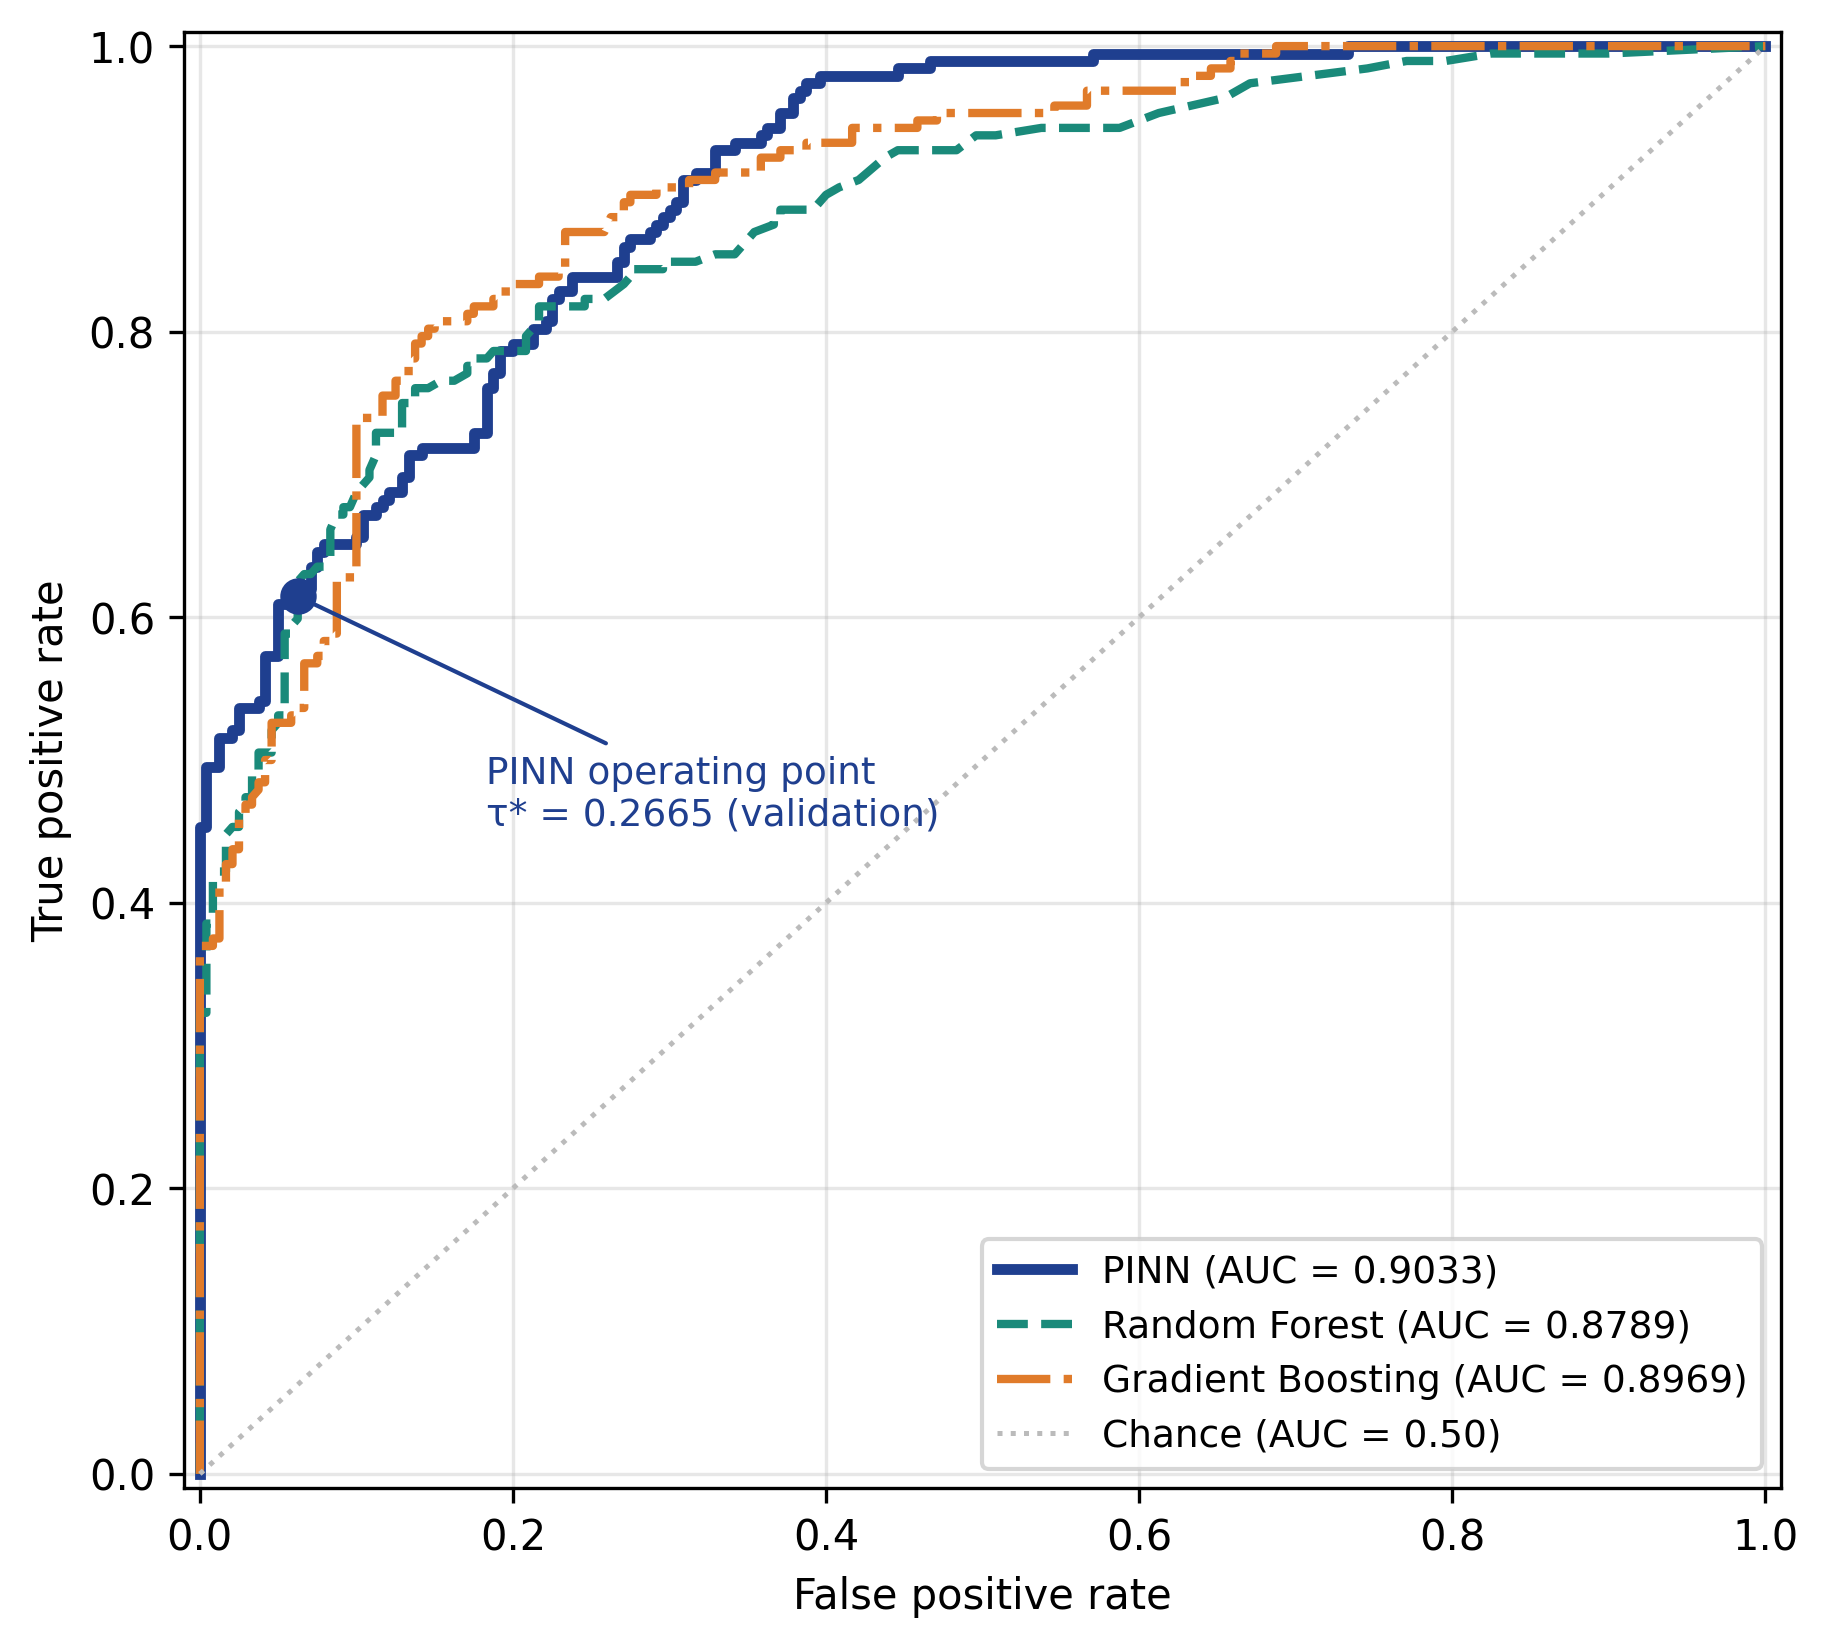

In [ ]:
if RUN["single_run"]:
    sr = {}
    pv, pt = run_pinn(W, y60, lam=1.0, seed=42); sr["PINN"] = evaluate(W, y60, pv, pt); probs_sr = {"PINN": (pv, pt)}
    for name, mdl in [("RF", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
                      ("GB", GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=42))]:
        pv, pt = run_sklearn(mdl, W, y60); sr[name] = evaluate(W, y60, pv, pt); probs_sr[name] = (pv, pt)
    yte = y60[W["te"]]
    tau = sr["PINN"]["test"]["tau"]; yhat = (probs_sr["PINN"][1] >= tau).astype(int)
    sr["PINN_confusion"] = dict(TN=int(((yhat == 0) & (yte == 0)).sum()), FP=int(((yhat == 1) & (yte == 0)).sum()),
                                FN=int(((yhat == 0) & (yte == 1)).sum()), TP=int(((yhat == 1) & (yte == 1)).sum()))
    for k in ("PINN", "RF", "GB"): print(k, sr[k]["test"])
    print(sr["PINN_confusion"])
    save("03_single_run_seed42", sr)

    fig, ax = plt.subplots(figsize=(6.2, 5.6), dpi=300)
    styles = {"PINN": ("#1f3f8f", "-", 2.6), "RF": ("#1a8a7a", "--", 2.0), "GB": ("#e07b2a", "-.", 2.0)}
    names = {"PINN": "PINN", "RF": "Random Forest", "GB": "Gradient Boosting"}
    for k in ("PINN", "RF", "GB"):
        fpr, tpr, _ = roc_curve(yte, probs_sr[k][1])
        c, ls, lw = styles[k]
        ax.plot(fpr, tpr, color=c, ls=ls, lw=lw, label=f"{names[k]} (AUC = {sr[k]['test']['auc']:.4f})")
    ax.plot([0, 1], [0, 1], color="#bbbbbb", ls=":", lw=1.2, label="Chance (AUC = 0.50)")
    p = probs_sr["PINN"][1]; tp_ = ((p >= tau) & (yte == 1)).sum() / (yte == 1).sum(); fp_ = ((p >= tau) & (yte == 0)).sum() / (yte == 0).sum()
    ax.scatter([fp_], [tp_], s=60, color="#1f3f8f", zorder=5)
    ax.annotate(f"PINN operating point\nτ* = {tau:.4f} (validation)", (fp_, tp_), xytext=(fp_ + 0.12, tp_ - 0.16),
                arrowprops=dict(arrowstyle="-", color="#1f3f8f"), fontsize=9, color="#1f3f8f")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01); ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=9)
    fig.tight_layout(); fig.savefig("results/figure4_roc_test.png", dpi=300); plt.show()

## 4. Ten seeds, same threshold rule for every model
Every model gets its threshold from the VALIDATION set by Youden's J. Macro F1
at τ = 0.5 is also stored, so it can be checked which rule produced Table 5.
Also trains the no-physics variant (λ = 0, ablation A4) with the same seeds.
Bootstrap CIs resample the 36 test SWEEPS (the independent unit), using
seed-averaged probabilities.

In [ ]:
if RUN["multiseed"]:
    MS = {k: {"val_p": [], "test_p": [], "res": []} for k in ("PINN", "A4_noPhysics", "RF", "GB")}
    for seed in range(N_SEEDS):
        for k, lam in (("PINN", 1.0), ("A4_noPhysics", 0.0)):
            pv, pt = run_pinn(W, y60, lam=lam, seed=seed)
            MS[k]["val_p"].append(pv); MS[k]["test_p"].append(pt); MS[k]["res"].append(evaluate(W, y60, pv, pt))
        for k, mdl in (("RF", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=seed)),
                       ("GB", GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=seed))):
            pv, pt = run_sklearn(mdl, W, y60)
            MS[k]["val_p"].append(pv); MS[k]["test_p"].append(pt); MS[k]["res"].append(evaluate(W, y60, pv, pt))
        print(f"seed {seed}: " + "  ".join(f"{k} F1={MS[k]['res'][-1]['test']['f1']:.4f}" for k in MS), f"({elapsed()})")

    summ = {}
    for k in MS:
        summ[k] = {f"{s}_{m}": msd([r[s][m] for r in MS[k]["res"]])
                   for s in ("test", "test_tau05") for m in ("acc", "f1", "auc")}
        summ[k]["tau"] = msd([r["test"]["tau"] for r in MS[k]["res"]])
    comps = {}
    for b in ("RF", "GB", "A4_noPhysics"):
        for s in ("test", "test_tau05"):
            for m in ("f1", "auc", "acc"):
                comps[f"PINN_vs_{b}_{s}_{m}"] = paired([r[s][m] for r in MS["PINN"]["res"]], [r[s][m] for r in MS[b]["res"]])
    # mixed rule check: PINN Youden vs baselines at 0.5 (what Table 5 may have used)
    for b in ("RF", "GB"):
        comps[f"PINN_youden_vs_{b}_tau05_f1"] = paired([r["test"]["f1"] for r in MS["PINN"]["res"]], [r["test_tau05"]["f1"] for r in MS[b]["res"]])

    # sweep-level bootstrap CIs
    te_s = sidw[W["te"]]; yte = y60[W["te"]]; uniq = np.unique(te_s)
    idx = {s: np.where(te_s == s)[0] for s in uniq}
    Pm = {k: np.mean(MS[k]["test_p"], 0) for k in MS}
    Tm = {k: youden(y60[W["va"]], np.mean(MS[k]["val_p"], 0)) for k in MS}
    rng = np.random.default_rng(0); boot = {}
    for _ in range(N_BOOT):
        ii = np.concatenate([idx[s] for s in rng.choice(uniq, len(uniq), replace=True)])
        if len(set(yte[ii])) < 2: continue
        vals = {}
        for k in MS:
            vals[f"AUC_{k}"] = roc_auc_score(yte[ii], Pm[k][ii])
            vals[f"F1_{k}"] = f1_score(yte[ii], (Pm[k][ii] >= Tm[k]).astype(int), average="macro")
        for b in ("RF", "GB", "A4_noPhysics"):
            vals[f"AUC_PINN-{b}"] = vals["AUC_PINN"] - vals[f"AUC_{b}"]
            vals[f"F1_PINN-{b}"] = vals["F1_PINN"] - vals[f"F1_{b}"]
        for kk, v in vals.items(): boot.setdefault(kk, []).append(v)
    ci = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in boot.items()}
    for k in summ: print(k, {m: [round(x, 4) for x in v] for m, v in summ[k].items()})
    for k, v in comps.items(): print(k, v)
    for k, v in ci.items(): print(f"95% CI {k}: [{v[0]:+.4f}, {v[1]:+.4f}]")
    save("04_multiseed", dict(n_seeds=N_SEEDS, summary_mean_sd=summ, paired_tests=comps,
                              sweep_bootstrap_ci95=ci, n_boot=len(next(iter(boot.values()))),
                              note="test = validation-Youden threshold per model; test_tau05 = fixed 0.5; SD uses ddof=1"))

seed 0: PINN F1=0.7209  A4_noPhysics F1=0.6979  RF F1=0.7661  GB F1=0.8198 (1.0 min)
seed 1: PINN F1=0.8395  A4_noPhysics F1=0.8022  RF F1=0.7592  GB F1=0.8153 (1.3 min)
seed 2: PINN F1=0.8159  A4_noPhysics F1=0.7677  RF F1=0.7750  GB F1=0.8198 (1.7 min)
seed 3: PINN F1=0.7605  A4_noPhysics F1=0.7567  RF F1=0.7639  GB F1=0.8198 (2.1 min)
seed 4: PINN F1=0.7796  A4_noPhysics F1=0.7721  RF F1=0.7430  GB F1=0.8198 (2.5 min)
seed 5: PINN F1=0.8161  A4_noPhysics F1=0.7904  RF F1=0.7500  GB F1=0.8198 (2.9 min)
seed 6: PINN F1=0.8297  A4_noPhysics F1=0.7848  RF F1=0.7523  GB F1=0.8153 (3.3 min)
seed 7: PINN F1=0.7787  A4_noPhysics F1=0.7675  RF F1=0.7569  GB F1=0.8153 (3.6 min)
seed 8: PINN F1=0.8430  A4_noPhysics F1=0.7839  RF F1=0.7866  GB F1=0.8198 (4.0 min)
seed 9: PINN F1=0.7871  A4_noPhysics F1=0.7327  RF F1=0.7707  GB F1=0.8198 (4.3 min)
PINN {'test_acc': [0.8042, 0.035], 'test_f1': [0.7971, 0.0388], 'test_auc': [0.909, 0.0206], 'test_tau05_acc': [0.7498, 0.0465], 'test_tau05_f1': [0.7

## 5. Ablation A1 (no sliding window), both versions (Table 6, Section 4.2)
* **unmatched:** single-point model on all 14 points of each sweep (same sweeps per split),
  so it has 336 more training points and is tested on 504 points.
* **matched-position:** single-point model trained and tested only on the 12 centre
  positions, i.e. exactly the same samples as the windowed model.
Both are compared with the full PINN of section 4 (same seeds).

In [ ]:
if RUN["ablation_A1"]:
    P_all = make_sets(Xp, zp, part_p)
    P_mat = make_sets(Xp, zp, part_p, mask=centre)
    yp = labels(socp)
    A1 = {"unmatched": [], "matched": []}
    for seed in range(N_SEEDS):
        for k, S in (("unmatched", P_all), ("matched", P_mat)):
            pv, pt = run_pinn(S, yp, lam=1.0, seed=seed); A1[k].append(evaluate(S, yp, pv, pt))
        print(f"seed {seed}: unmatched F1={A1['unmatched'][-1]['test']['f1']:.4f}  matched F1={A1['matched'][-1]['test']['f1']:.4f} ({elapsed()})")
    out = {"n_train": {"unmatched": int(P_all["tr"].sum()), "matched": int(P_mat["tr"].sum())},
           "n_test": {"unmatched": int(P_all["te"].sum()), "matched": int(P_mat["te"].sum())}}
    full = [r["test"]["f1"] for r in MS["PINN"]["res"]] if RUN["multiseed"] else None
    for k in A1:
        out[k] = {"acc": msd([r["test"]["acc"] for r in A1[k]]), "f1": msd([r["test"]["f1"] for r in A1[k]]),
                  "auc": msd([r["test"]["auc"] for r in A1[k]])}
        if full is not None:
            out[k]["vs_full_f1"] = paired([r["test"]["f1"] for r in A1[k]], full)
        print(k, out[k])
    save("05_ablation_A1", out)

seed 0: unmatched F1=0.8246  matched F1=0.8027 (5.0 min)
seed 1: unmatched F1=0.8259  matched F1=0.8127 (5.2 min)
seed 2: unmatched F1=0.7733  matched F1=0.7668 (5.4 min)
seed 3: unmatched F1=0.7843  matched F1=0.8029 (5.5 min)
seed 4: unmatched F1=0.8256  matched F1=0.7520 (5.7 min)
seed 5: unmatched F1=0.7897  matched F1=0.7831 (5.8 min)
seed 6: unmatched F1=0.8022  matched F1=0.8304 (6.0 min)
seed 7: unmatched F1=0.8099  matched F1=0.8051 (6.2 min)
seed 8: unmatched F1=0.8281  matched F1=0.7702 (6.4 min)
seed 9: unmatched F1=0.8281  matched F1=0.7875 (6.6 min)
unmatched {'acc': [0.8168650793650795, 0.020343081081827186], 'f1': [0.8091799272494866, 0.020659658796095468], 'auc': [0.9322879464285713, 0.012502811667683807], 'vs_full_f1': {'delta': 0.012088757503361924, 'p': 0.41882698163127585}}
matched {'acc': [0.7976851851851852, 0.021938561660476485], 'f1': [0.7913299843038744, 0.023831736153107484], 'auc': [0.909900173611111, 0.026599244019773996], 'vs_full_f1': {'delta': -0.0057611

## 6. Physical-consistency metric
The physics prior says: a window with high impedance magnitude (z_norm > 0.5,
training-set scaling) should not be labelled High SoC. For each model we report,
on the test set, the share of those high-impedance windows that the model labels
High SoC at its own validation threshold (lower = more consistent with the prior),
split by true class, plus the mean predicted P(High SoC) on those windows.
Note from Section 4.5 that the prior itself only holds for the lower half of the SoC range.

In [ ]:
if RUN["consistency"] and RUN["multiseed"]:
    hi = W["zn"][W["te"]] > 0.5; yte = y60[W["te"]]
    cons = {"n_high_impedance_test_windows": int(hi.sum()),
            "n_high_impedance_true_low": int((hi & (yte == 0)).sum()),
            "n_high_impedance_true_high": int((hi & (yte == 1)).sum())}
    per = {}
    for k in MS:
        v_all, v_low, v_high, mp = [], [], [], []
        for pv, pt, r in zip(MS[k]["val_p"], MS[k]["test_p"], MS[k]["res"]):
            pred = pt >= r["test"]["tau"]
            v_all.append(pred[hi].mean()); v_low.append(pred[hi & (yte == 0)].mean() if (hi & (yte == 0)).any() else np.nan)
            v_high.append(pred[hi & (yte == 1)].mean() if (hi & (yte == 1)).any() else np.nan); mp.append(pt[hi].mean())
        per[k] = dict(violation_rate=v_all, violation_rate_true_low=v_low, violation_rate_true_high=v_high, mean_p_high=mp)
        cons[k] = {m: msd(v) for m, v in per[k].items()}
        print(k, {m: [round(x, 4) for x in v] for m, v in cons[k].items()})
    for b in ("A4_noPhysics", "RF", "GB"):
        cons[f"PINN_vs_{b}"] = {m: paired(per["PINN"][m], per[b][m]) for m in per["PINN"]}
        print("PINN vs", b, cons[f"PINN_vs_{b}"])
    save("06_physical_consistency", cons)

PINN {'violation_rate': [0.3978, 0.0367], 'violation_rate_true_low': [0.0986, 0.0563], 'violation_rate_true_high': [0.8793, 0.0556], 'mean_p_high': [0.3472, 0.0254]}
A4_noPhysics {'violation_rate': [0.5189, 0.0524], 'violation_rate_true_low': [0.255, 0.0757], 'violation_rate_true_high': [0.9437, 0.0206], 'mean_p_high': [0.3937, 0.0229]}
RF {'violation_rate': [0.4, 0.0238], 'violation_rate_true_low': [0.1186, 0.0316], 'violation_rate_true_high': [0.8529, 0.0151], 'mean_p_high': [0.3002, 0.0013]}
GB {'violation_rate': [0.326, 0.0], 'violation_rate_true_low': [0.0071, 0.0], 'violation_rate_true_high': [0.8391, 0.0], 'mean_p_high': [0.3051, 0.0002]}
PINN vs A4_noPhysics {'violation_rate': {'delta': -0.12114537444933919, 'p': 8.041217053899214e-05}, 'violation_rate_true_low': {'delta': -0.15642857142857142, 'p': 7.566747802365976e-05}, 'violation_rate_true_high': {'delta': -0.064367816091954, 'p': 0.007381481793307972}, 'mean_p_high': {'delta': -0.0464979499578476, 'p': 0.000592229625911776

## 7. Stronger, validation-tuned baselines
Hyperparameters chosen by validation AUC (threshold-free); threshold then by
validation Youden's J, exactly as for the PINN. RF and GB are re-run over the 10
seeds with their best settings; SVM and logistic regression are deterministic.

In [ ]:
if RUN["strong_baselines"] and RUN["multiseed"]:
    from itertools import product
    Xtr, Xva = W["Xs"][W["tr"]], W["Xs"][W["va"]]; ytr, yva = y60[W["tr"]], y60[W["va"]]
    grids = {
        "RF_tuned": (lambda p, s: RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=s, n_jobs=-1, **p),
                     [dict(max_depth=d, min_samples_leaf=l, max_features=f) for d, l, f in product([None, 5, 10, 20], [1, 5, 20], ["sqrt", 0.5, 1.0])]),
        "GB_tuned": (lambda p, s: GradientBoostingClassifier(random_state=s, **p),
                     [dict(n_estimators=e, max_depth=d, learning_rate=r, subsample=ss) for e, d, r, ss in product([100, 300, 600], [2, 3, 5], [0.03, 0.1], [1.0, 0.8])]),
        "SVM_RBF": (lambda p, s: SVC(kernel="rbf", probability=True, random_state=0, **p),
                    [dict(C=c, gamma=g) for c, g in product([0.1, 1, 10, 100], ["scale", 0.01, 0.1, 1])]),
        "LogReg": (lambda p, s: LogisticRegression(max_iter=5000, **p), [dict(C=c) for c in [0.01, 0.1, 1, 10, 100]]),
    }
    if QUICK: grids = {k: (f, g[:2]) for k, (f, g) in grids.items()}
    SB = {}
    for name, (make, grid) in grids.items():
        scores = []
        for p in grid:
            m = make(p, 0).fit(Xtr, ytr); scores.append(roc_auc_score(yva, m.predict_proba(Xva)[:, 1]))
        best = grid[int(np.argmax(scores))]
        seeds = range(N_SEEDS) if name in ("RF_tuned", "GB_tuned") else [0]
        res = []
        for s in seeds:
            pv, pt = run_sklearn(make(best, s), W, y60); res.append(evaluate(W, y60, pv, pt))
        if len(res) == 1: res = res * N_SEEDS            # deterministic model: same result every seed
        SB[name] = dict(best_params={k: (v if v is not None else "None") for k, v in best.items()}, best_val_auc=float(max(scores)),
                        test_f1=msd([r["test"]["f1"] for r in res]), test_auc=msd([r["test"]["auc"] for r in res]),
                        test_acc=msd([r["test"]["acc"] for r in res]))
        if RUN["multiseed"]:
            pf = [r["test"]["f1"] for r in MS["PINN"]["res"]]; pa = [r["test"]["auc"] for r in MS["PINN"]["res"]]
            f, a = [r["test"]["f1"] for r in res], [r["test"]["auc"] for r in res]
            if np.std(f) == 0:
                SB[name]["PINN_vs_f1"] = dict(delta=float(np.mean(pf) - f[0]), p=float(stats.ttest_1samp(pf, f[0]).pvalue))
                SB[name]["PINN_vs_auc"] = dict(delta=float(np.mean(pa) - a[0]), p=float(stats.ttest_1samp(pa, a[0]).pvalue))
            else:
                SB[name]["PINN_vs_f1"] = paired(pf, f); SB[name]["PINN_vs_auc"] = paired(pa, a)
        print(name, SB[name], elapsed())
    save("07_strong_baselines", SB)

RF_tuned {'best_params': {'max_depth': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt'}, 'best_val_auc': 0.8794397144822843, 'test_f1': [0.809205742413897, 0.003807856054203876], 'test_auc': [0.8894118923611112, 0.0020677955703070094], 'test_acc': [0.8099537037037038, 0.0036924339858041533], 'PINN_vs_f1': {'delta': -0.012114572667772317, 'p': 0.33414454260580934}, 'PINN_vs_auc': {'delta': 0.019557291666666664, 'p': 0.016277460696867238}} 8.2 min
GB_tuned {'best_params': {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1, 'subsample': 0.8}, 'best_val_auc': 0.8955538355693154, 'test_f1': [0.8252602300613001, 0.011446827309302373], 'test_auc': [0.9006868489583333, 0.0031653709363319237], 'test_acc': [0.826851851851852, 0.011793193317618985], 'PINN_vs_f1': {'delta': -0.02816906031517541, 'p': 0.035560859123246163}, 'PINN_vs_auc': {'delta': 0.008282335069444435, 'p': 0.229549409275669}} 11.1 min
SVM_RBF {'best_params': {'C': 100, 'gamma': 0.1}, 'best_val_auc': 0.9215041279669762, 

## 8. λ = 0 row for Table 7 (validation set, 8 seeds)

In [ ]:
if RUN["lambda0"]:
    L0 = []
    for seed in range(N_SEEDS_LAMBDA):
        pv, pt = run_pinn(W, y60, lam=0.0, seed=seed); L0.append(evaluate(W, y60, pv, pt))
    out = {"n_seeds": N_SEEDS_LAMBDA, "val_acc": msd([r["val"]["acc"] for r in L0]), "val_f1": msd([r["val"]["f1"] for r in L0]),
           "note": "Table 7 lists lambda=0 macro F1 0.7663 +/- 0.0303; check val_f1 matches before using val_acc"}
    print(out); save("08_lambda0", out)

{'n_seeds': 8, 'val_acc': [0.8136574074074074, 0.017454554524334167], 'val_f1': [0.8101353282889312, 0.018781022036884015], 'note': 'Table 7 lists lambda=0 macro F1 0.7663 +/- 0.0303; check val_f1 matches before using val_acc'}
saved results/08_lambda0.json (12.4 min)


## 9. Sensitivity to the SoC class cutoff
Full model (λ = 1) vs no-physics (λ = 0) at cutoffs of 50% and 70%, same split,
same seeds; z_norm and thresholds are re-derived for each cutoff. The 60% result
comes from section 4.

In [ ]:
if RUN["cutoffs"]:
    CUT = {}
    for cutoff in (50, 70):
        y = labels(socw, cutoff); r_full, r_nop = [], []
        for seed in range(N_SEEDS_CUTOFF):
            pv, pt = run_pinn(W, y, lam=1.0, seed=seed); r_full.append(evaluate(W, y, pv, pt))
            pv, pt = run_pinn(W, y, lam=0.0, seed=seed); r_nop.append(evaluate(W, y, pv, pt))
            print(f"cutoff {cutoff} seed {seed}: full F1={r_full[-1]['test']['f1']:.4f}  noPhys F1={r_nop[-1]['test']['f1']:.4f} ({elapsed()})")
        CUT[str(cutoff)] = dict(
            class_balance_train=[int((y[W['tr']] == 0).sum()), int((y[W['tr']] == 1).sum())],
            class_balance_test=[int((y[W['te']] == 0).sum()), int((y[W['te']] == 1).sum())],
            full=dict(f1=msd([r["test"]["f1"] for r in r_full]), auc=msd([r["test"]["auc"] for r in r_full]), acc=msd([r["test"]["acc"] for r in r_full])),
            no_physics=dict(f1=msd([r["test"]["f1"] for r in r_nop]), auc=msd([r["test"]["auc"] for r in r_nop]), acc=msd([r["test"]["acc"] for r in r_nop])),
            full_vs_no_physics_f1=paired([r["test"]["f1"] for r in r_full], [r["test"]["f1"] for r in r_nop]),
            full_youden_vs_tau05_f1=paired([r["test"]["f1"] for r in r_full], [r["test_tau05"]["f1"] for r in r_full]))
        print(cutoff, CUT[str(cutoff)])
    save("09_cutoff_sensitivity", CUT)

cutoff 50 seed 0: full F1=0.8679  noPhys F1=0.7775 (12.5 min)
cutoff 50 seed 1: full F1=0.7836  noPhys F1=0.7773 (12.7 min)
cutoff 50 seed 2: full F1=0.7883  noPhys F1=0.8332 (13.0 min)
cutoff 50 seed 3: full F1=0.7626  noPhys F1=0.7778 (13.0 min)
cutoff 50 seed 4: full F1=0.8329  noPhys F1=0.7166 (13.3 min)
cutoff 50 seed 5: full F1=0.8514  noPhys F1=0.7586 (13.5 min)
cutoff 50 seed 6: full F1=0.8217  noPhys F1=0.7636 (13.6 min)
cutoff 50 seed 7: full F1=0.8004  noPhys F1=0.8148 (13.7 min)
cutoff 50 seed 8: full F1=0.7736  noPhys F1=0.7870 (13.9 min)
cutoff 50 seed 9: full F1=0.8007  noPhys F1=0.7893 (14.0 min)
50 {'class_balance_train': [792, 1224], 'class_balance_test': [192, 240], 'full': {'f1': [0.8083098867103631, 0.03435717094840392], 'auc': [0.9327604166666668, 0.01824101590750285], 'acc': [0.8090277777777777, 0.03390235767564079]}, 'no_physics': {'f1': [0.7795668032116927, 0.03152661197788637], 'auc': [0.8985134548611111, 0.021472254972554915], 'acc': [0.7798611111111111, 0.03

## 10. Fitted Randles parameters
Model per sweep: Z = Rs + jωL + 1 / ( Q(jω)^n + 1/(Rct + Zw) ),  Zw = σ(1 − j)/√ω.
Fitted by modulus-weighted nonlinear least squares (several starts) on all 14
points. Fit quality is reported; check it before using the fitted Rct.

         rel_rmse
count  240.000000
mean     0.003392
std      0.000862
min      0.001781
25%      0.002629
50%      0.003423
75%      0.003979
max      0.006554
{'median_rel_rmse': 0.003423471324679547, 'p90_rel_rmse': 0.004394261649022245, 'n_fits_at_bound': 0, 'median_n': 0.6186370081767064, 'spearman_Rct_vs_SoC_full_range': {'2': -0.09515679698426281, '3': -0.15111167408416382, '5': -0.6258904815725456, '6': -0.48483058181770516}, 'spearman_Rct_vs_SoC_10_to_50': {'2': -0.9040919624704303, '3': -0.9177078052787198, '5': -0.9286004795253516, '6': -0.9013687939087722}, 'soc_of_min_mean_Rct': {'2': 50, '3': 50, '5': 100, '6': 50}}
saved results/10_rct_fit_summary.json (19.1 min)


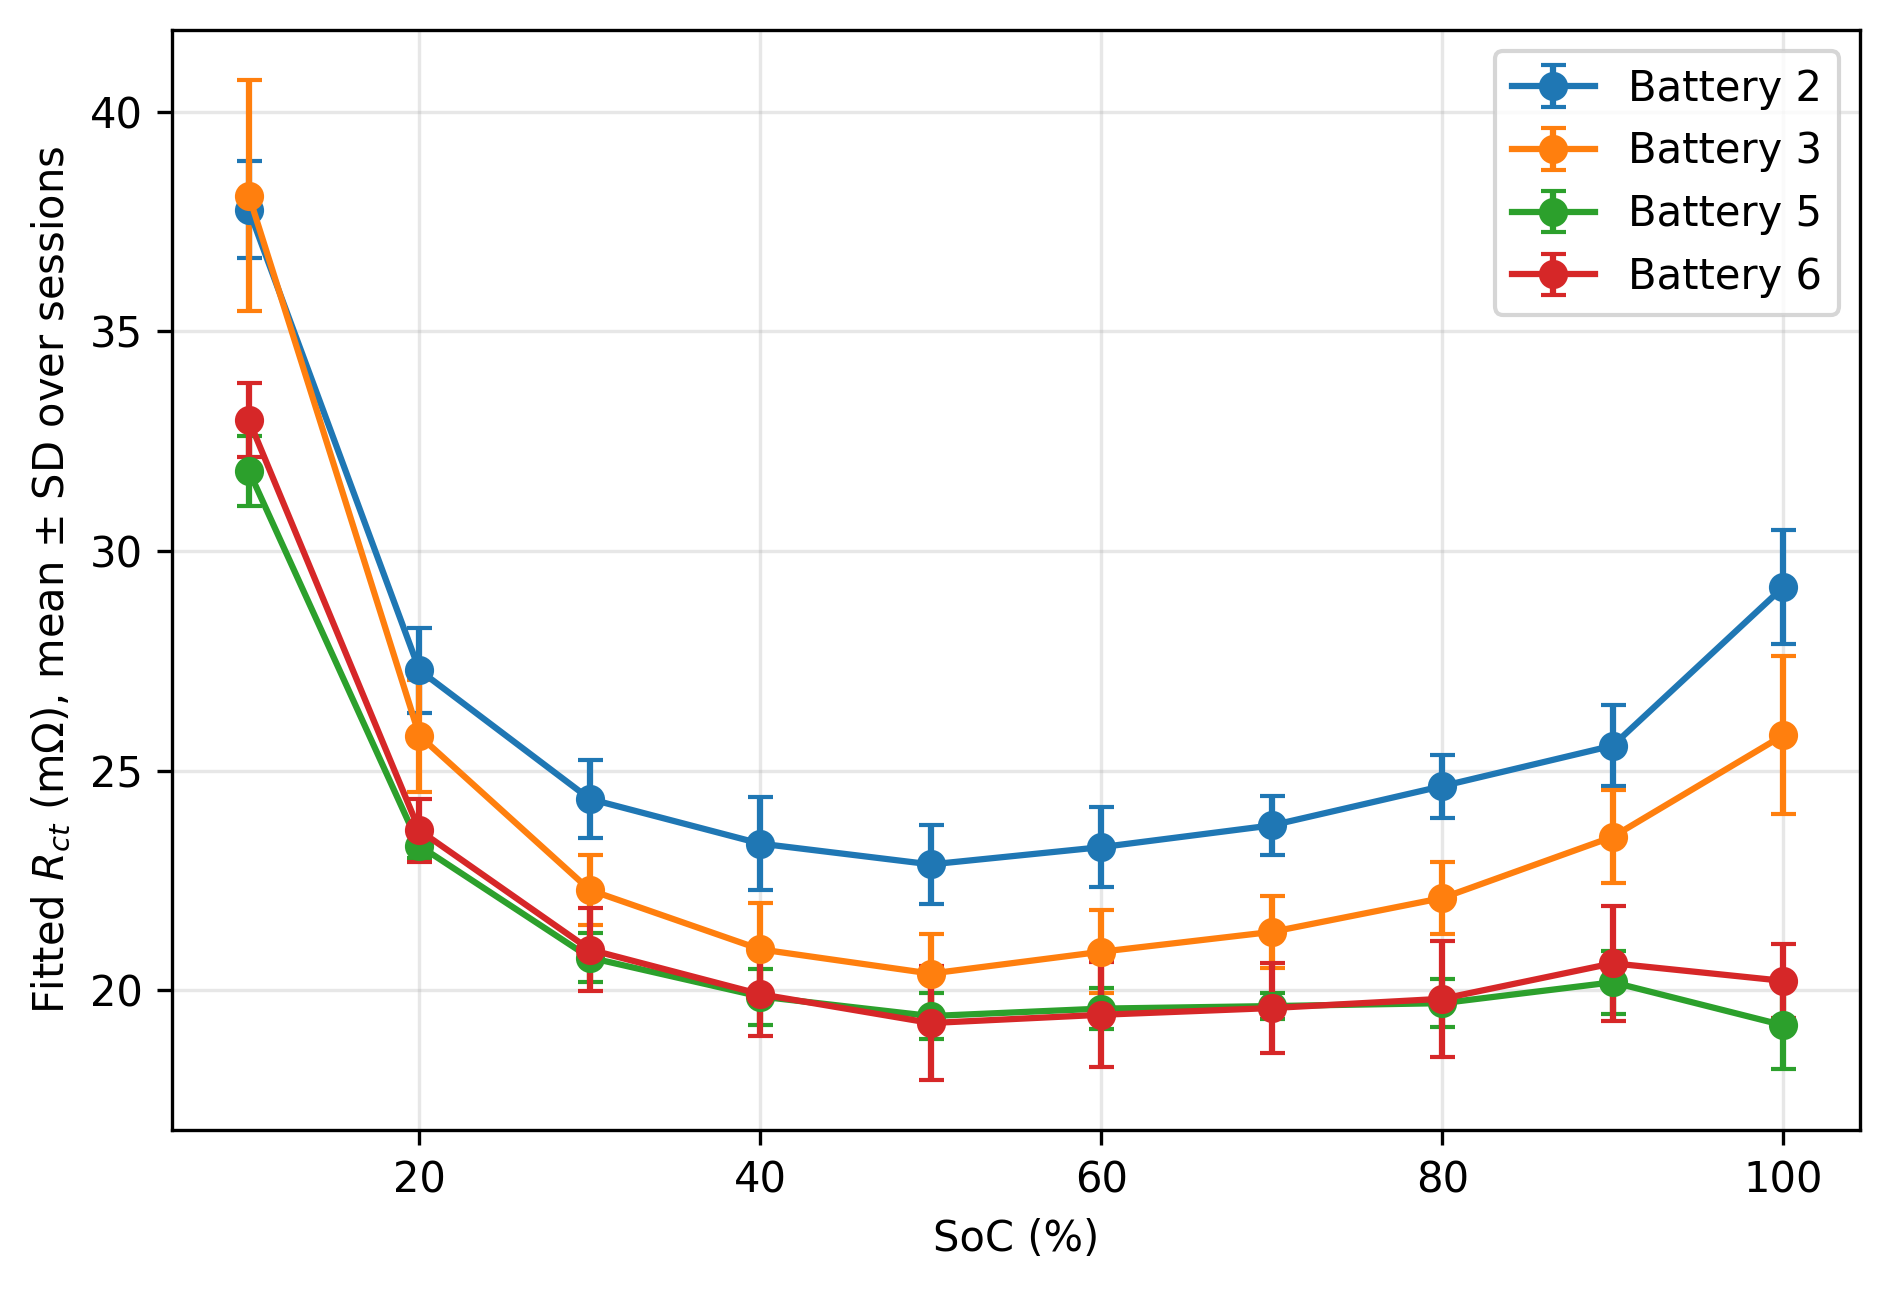

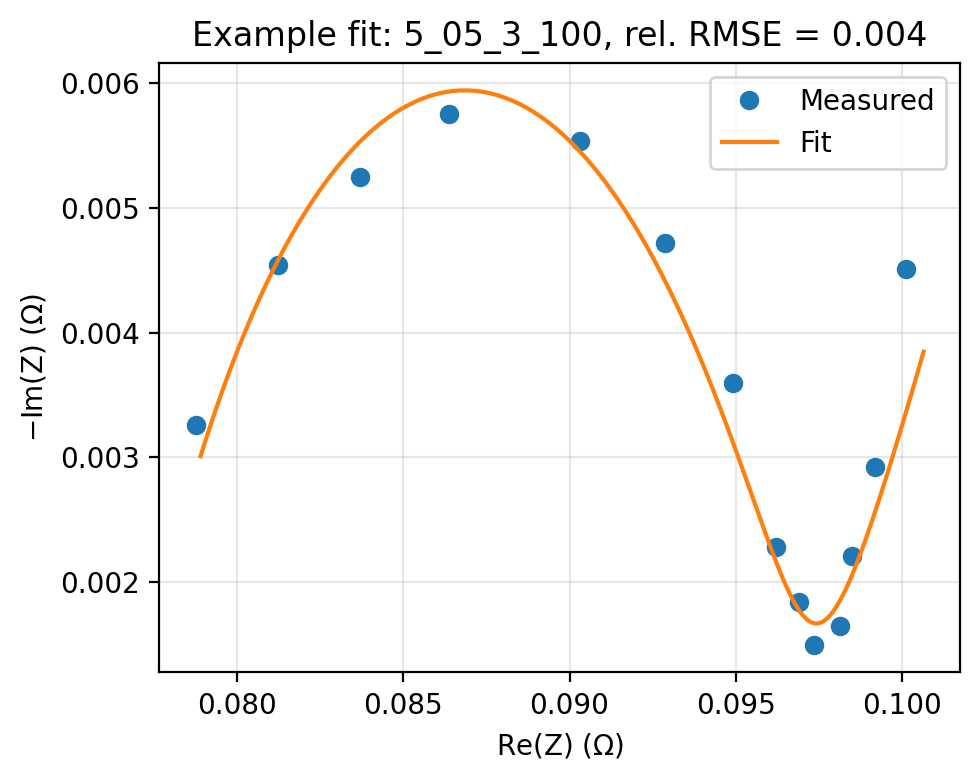

In [ ]:
if RUN["rct_fit"]:
    def model_Z(theta, w):
        Rs, Rct, Q, n_, sig, L = theta
        Zw = sig * (1 - 1j) / np.sqrt(w)
        return Rs + 1j * w * L + 1.0 / (Q * (1j * w) ** n_ + 1.0 / (Rct + Zw))
    def resid(x, w, Z):
        Rs, Rct, Q, sig, L = np.exp(x[:5]); n_ = x[5]
        r = (model_Z((Rs, Rct, Q, n_, sig, L), w) - Z) / np.abs(Z)
        return np.concatenate([r.real, r.imag])
    rows = []
    for key, g in df.groupby("SWEEP_ID", sort=False):
        g = g.sort_values(freq_col)
        w = 2 * np.pi * g[freq_col].values.astype(float); Z = g["Z_complex"].values.astype(complex)
        Rs0 = max(Z.real.min(), 1e-6); Rct0 = max(Z.real.max() - Z.real.min(), 1e-6)
        best = None
        for Q0 in (1e-2, 1e-1, 1.0, 10.0):
            for sig0 in (1e-4, 1e-3, 1e-2):
                x0 = np.r_[np.log([Rs0, Rct0, Q0, sig0, 1e-8]), 0.8]
                lo = np.r_[np.log([1e-7, 1e-7, 1e-6, 1e-8, 1e-12]), 0.4]
                hi = np.r_[np.log([10, 10, 1e4, 10, 1e-3]), 1.0]
                try:
                    s = least_squares(resid, x0, bounds=(lo, hi), args=(w, Z), max_nfev=4000)
                    if best is None or s.cost < best.cost: best = s
                except Exception:
                    pass
        Rs, Rct, Q, sig, L = np.exp(best.x[:5]); n_ = best.x[5]
        rel_err = float(np.sqrt(np.mean(np.abs(model_Z((Rs, Rct, Q, n_, sig, L), w) - Z) ** 2)) / np.mean(np.abs(Z)))
        parts = key.split("_"); b, m, soc = parts[0], "_".join(parts[1:-1]), parts[-1]
        rows.append(dict(sweep=key, battery=b, session=m, soc=int(float(soc)), Rs=Rs, Rct=Rct, Q=Q, n=n_, sigma=sig, L=L,
                         rel_rmse=rel_err, Rct_at_bound=bool(Rct < 1.01e-7 or Rct > 9.9)))
    fits = pd.DataFrame(rows); fits.to_csv("results/10_randles_fits_per_sweep.csv", index=False)
    print(fits[["rel_rmse"]].describe())
    agg = fits.groupby(["battery", "soc"])[["Rct", "Rs", "rel_rmse"]].agg(["mean", "std"]).reset_index()
    agg.columns = ["_".join(c).strip("_") for c in agg.columns]; agg.to_csv("results/10_fitted_Rct_by_battery_soc.csv", index=False)
    rho = {b: float(stats.spearmanr(g["soc"], g["Rct"]).correlation) for b, g in fits.groupby("battery")}
    lowhalf = {b: float(stats.spearmanr(g[g.soc <= 50]["soc"], g[g.soc <= 50]["Rct"]).correlation) for b, g in fits.groupby("battery")}
    summary = dict(median_rel_rmse=float(fits.rel_rmse.median()), p90_rel_rmse=float(fits.rel_rmse.quantile(0.9)),
                   n_fits_at_bound=int(fits.Rct_at_bound.sum()), median_n=float(fits.n.median()),
                   spearman_Rct_vs_SoC_full_range=rho, spearman_Rct_vs_SoC_10_to_50=lowhalf,
                   soc_of_min_mean_Rct={b: int(g.groupby("soc").Rct.mean().idxmin()) for b, g in fits.groupby("battery")})
    print(summary); save("10_rct_fit_summary", summary)
    fig, ax = plt.subplots(figsize=(6.4, 4.4), dpi=300)
    for b, g in agg.groupby("battery"):
        ax.errorbar(g["soc"], g["Rct_mean"] * 1e3, yerr=g["Rct_std"] * 1e3, marker="o", capsize=3, label=f"Battery {b}")
    ax.set_xlabel("SoC (%)"); ax.set_ylabel("Fitted $R_{ct}$ (mΩ), mean ± SD over sessions")
    ax.grid(alpha=0.3); ax.legend(); fig.tight_layout(); fig.savefig("results/figure_fitted_Rct_vs_SoC.png", dpi=300); plt.show()
    # example fit for visual check
    ex = fits.iloc[len(fits) // 2]; g = df[df.SWEEP_ID == ex.sweep].sort_values(freq_col)
    w = 2 * np.pi * g[freq_col].values.astype(float); Z = g["Z_complex"].values.astype(complex)
    wf = np.logspace(np.log10(w.min()), np.log10(w.max()), 200)
    Zf = model_Z((ex.Rs, ex.Rct, ex.Q, ex.n, ex.sigma, ex.L), wf)
    fig, ax = plt.subplots(figsize=(5, 4), dpi=200)
    ax.plot(Z.real, -Z.imag, "o", label="measured"); ax.plot(Zf.real, -Zf.imag, "-", label="fit")
    ax.set_xlabel("Re(Z) (Ω)"); ax.set_ylabel("−Im(Z) (Ω)"); ax.set_title(f"Example fit: {ex.sweep}, rel. RMSE {ex.rel_rmse:.3f}")
    ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); fig.savefig("results/figure_example_fit.png", dpi=200); plt.show()

## 11. Versions and download

In [ ]:
versions = dict(python=platform.python_version(), torch=torch.__version__, sklearn=sklearn.__version__,
                numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__,
                quick_mode=QUICK, total_minutes=round((time.time() - T0) / 60, 1))
print(versions); save("11_versions", versions)
with zipfile.ZipFile("reviewer_results_v2.zip", "w") as zf:
    for fn in sorted(os.listdir("results")):
        zf.write(os.path.join("results", fn), fn)
print("wrote reviewer_results_v2.zip")
try:
    from google.colab import files; files.download("reviewer_results_v2.zip")
except ImportError:
    pass

{'python': '3.13.16', 'torch': '2.11.0+cpu', 'sklearn': '1.6.1', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'quick_mode': False, 'total_minutes': 19.2}
saved results/11_versions.json (19.2 min)
wrote reviewer_results_v2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PINN exact-ROC tau* = 0.1959 | test metrics: {'acc': 0.7939814814814815, 'f1': 0.7879257563639372, 'auc': 0.9032769097222223, 'tau': 0.19590771198272705}


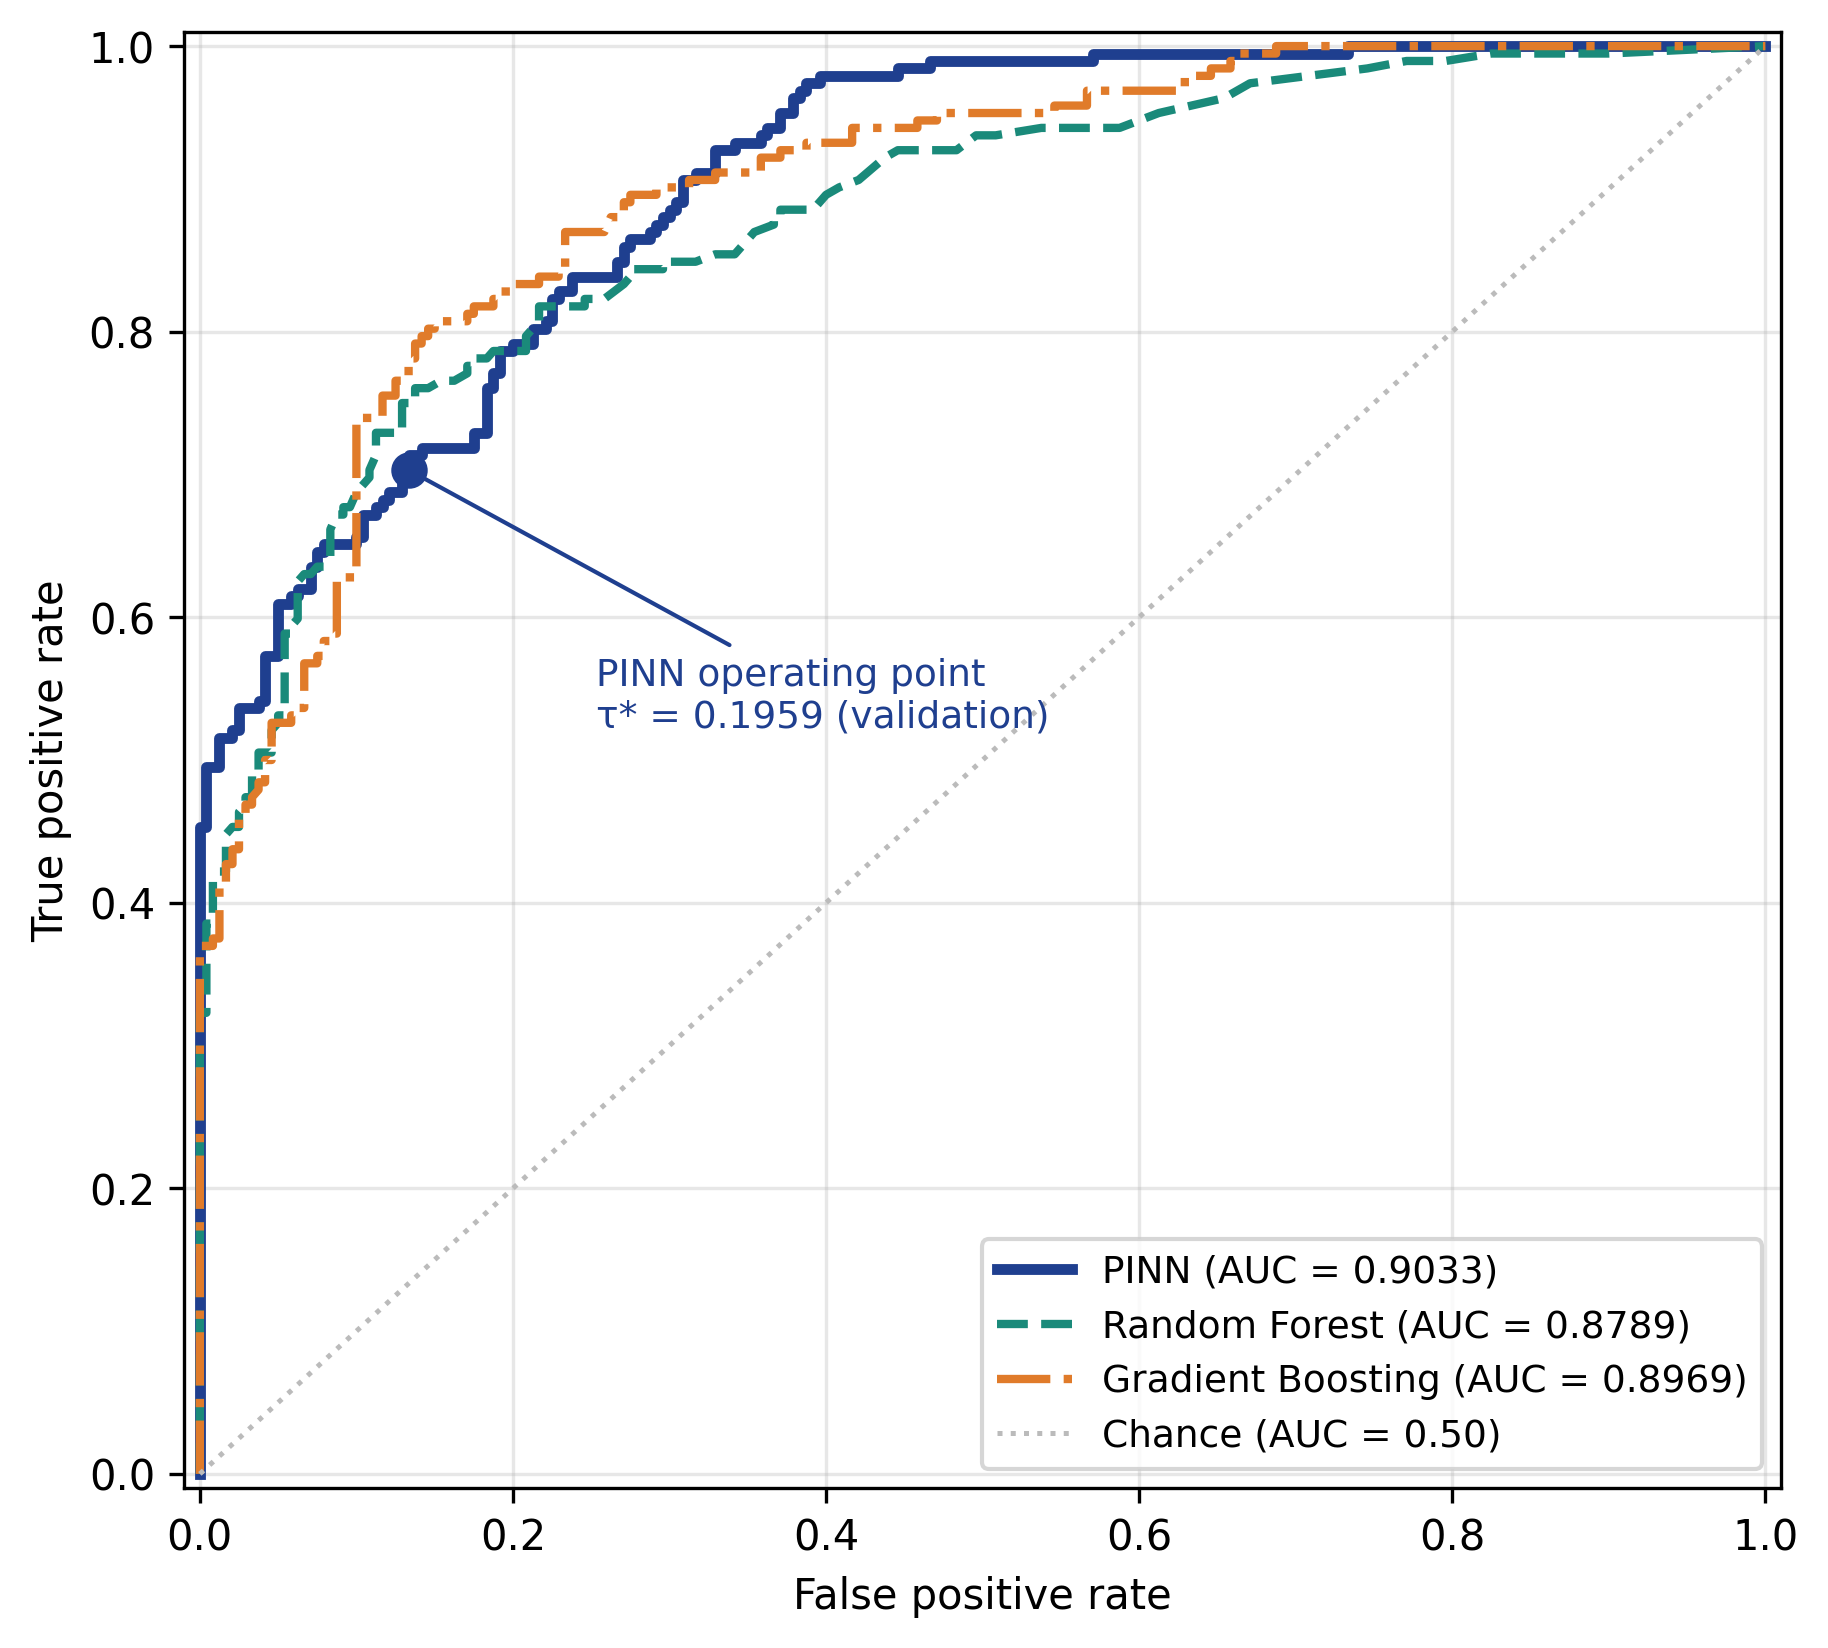

lambda 0.0 {'tau05': (0.7355, 0.7293), 'youden_exact': (0.8142, 0.8107), 'youden_grid': (0.8137, 0.8101)}
lambda 1.0 {'tau05': (0.728, 0.7178), 'youden_exact': (0.8354, 0.834), 'youden_grid': (0.8348, 0.8334)}
saved results/12_fig4_and_table7_protocol.json (41.2 min)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# === Follow-up cell (about 3-5 minutes) ===
# Run after sections 0-1
# (set every RUN flag to False to skip the rest). It does two things:
#   A. redraws Figure 4 with the PINN operating point at the exact-ROC Youden threshold
#      used in Table 3 (tau* = 0.1959), instead of the 500-point grid;
#   B. finds which validation protocol reproduces Table 7, so the lambda = 0 row can be filled.

def youden_exact(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[int(np.argmax(tpr - fpr))])

# ---------- A. Figure 4 ----------
pv, pt = run_pinn(W, y60, lam=1.0, seed=42)
tau_exact = youden_exact(y60[W["va"]], pv)
models = {"PINN": pt}
for name, mdl in [("RF", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
                  ("GB", GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=42))]:
    models[name] = run_sklearn(mdl, W, y60)[1]
yte = y60[W["te"]]
print("PINN exact-ROC tau* =", round(tau_exact, 4), "| test metrics:", metrics(yte, pt, tau_exact))

fig, ax = plt.subplots(figsize=(6.2, 5.6), dpi=300)
styles = {"PINN": ("#1f3f8f", "-", 2.6, "PINN"), "RF": ("#1a8a7a", "--", 2.0, "Random Forest"), "GB": ("#e07b2a", "-.", 2.0, "Gradient Boosting")}
for k, p in models.items():
    fpr, tpr, _ = roc_curve(yte, p); c, ls, lw, lab = styles[k]
    ax.plot(fpr, tpr, color=c, ls=ls, lw=lw, label=f"{lab} (AUC = {roc_auc_score(yte, p):.4f})")
ax.plot([0, 1], [0, 1], color="#bbbbbb", ls=":", lw=1.2, label="Chance (AUC = 0.50)")
fp_ = ((pt >= tau_exact) & (yte == 0)).sum() / (yte == 0).sum(); tp_ = ((pt >= tau_exact) & (yte == 1)).sum() / (yte == 1).sum()
ax.scatter([fp_], [tp_], s=60, color="#1f3f8f", zorder=5)
ax.annotate(f"PINN operating point\nτ* = {tau_exact:.4f} (validation)", (fp_, tp_), xytext=(fp_ + 0.12, tp_ - 0.18),
            arrowprops=dict(arrowstyle="-", color="#1f3f8f"), fontsize=9, color="#1f3f8f")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01); ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig("results/figure4_roc_test_exact_tau.png", dpi=300); plt.show()

# ---------- B. which validation protocol reproduces Table 7? ----------
# Table 7 (8 seeds): lambda = 1.0 -> val acc 0.8006, val macro F1 0.7931; lambda = 0 -> val macro F1 0.7663
proto = {}
for lam in (0.0, 1.0):
    rows = {"tau05": [], "youden_exact": [], "youden_grid": []}
    for seed in range(8):
        pv, _ = run_pinn(W, y60, lam=lam, seed=seed); yv = y60[W["va"]]
        for k, tau in (("tau05", 0.5), ("youden_exact", youden_exact(yv, pv)), ("youden_grid", youden(yv, pv))):
            yhat = (pv >= tau).astype(int)
            rows[k].append((accuracy_score(yv, yhat), f1_score(yv, yhat, average="macro")))
    proto[str(lam)] = {k: {"val_acc": msd([a for a, _ in v]), "val_f1": msd([f for _, f in v])} for k, v in rows.items()}
    print("lambda", lam, {k: (round(v["val_acc"][0], 4), round(v["val_f1"][0], 4)) for k, v in proto[str(lam)].items()})
save("12_fig4_and_table7_protocol", dict(tau_exact=tau_exact, single_run_exact=metrics(yte, pt, tau_exact), table7_protocol=proto))
with zipfile.ZipFile("reviewer_results_v3.zip", "w") as zf:
    for fn in ("12_fig4_and_table7_protocol.json", "figure4_roc_test_exact_tau.png"):
        zf.write(os.path.join("results", fn), fn)
try:
    from google.colab import files; files.download("reviewer_results_v3.zip")
except ImportError:
    pass


In [ ]:
# === λ sweep on the VALIDATION set (about 8-12 minutes) ===
# Run after sections 0-1
# (all RUN flags can stay False). Same 8 seeds (0-7) and λ grid as Table 7.
# For each λ and seed: threshold by Youden's J (exact ROC thresholds) on the validation set,
# validation accuracy / macro F1 at that threshold, and, for reference only, the test macro F1.

def youden_exact(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[int(np.argmax(tpr - fpr))])

LAMS = [0.0, 0.01, 0.05, 0.10, 0.50, 1.0, 2.0, 5.0]
SEEDS = range(8)
yv, yt = y60[W["va"]], y60[W["te"]]
sweep = {}
for lam in LAMS:
    va_acc, va_f1, te_f1, te_acc = [], [], [], []
    for seed in SEEDS:
        pv, pt = run_pinn(W, y60, lam=lam, seed=seed)
        tau = youden_exact(yv, pv)
        va_acc.append(accuracy_score(yv, (pv >= tau).astype(int))); va_f1.append(f1_score(yv, (pv >= tau).astype(int), average="macro"))
        te_acc.append(accuracy_score(yt, (pt >= tau).astype(int))); te_f1.append(f1_score(yt, (pt >= tau).astype(int), average="macro"))
    sweep[str(lam)] = dict(val_acc=va_acc, val_f1=va_f1, test_acc=te_acc, test_f1=te_f1)
    print(f"λ={lam}: val acc {np.mean(va_acc):.4f}  val F1 {np.mean(va_f1):.4f} ± {np.std(va_f1, ddof=1):.4f}   (test F1 {np.mean(te_f1):.4f}, test acc {np.mean(te_acc):.4f})  {elapsed()}")

out = {"n_seeds": len(SEEDS), "threshold": "Youden J, exact ROC thresholds, validation set", "per_lambda": {}}
for lam in LAMS:
    r = sweep[str(lam)]
    e = {k: msd(v) for k, v in r.items()}
    if lam != 0.0:
        e["val_f1_vs_lambda0"] = paired(r["val_f1"], sweep["0.0"]["val_f1"])
        e["test_f1_vs_lambda0"] = paired(r["test_f1"], sweep["0.0"]["test_f1"])
    out["per_lambda"][str(lam)] = e
best = max(LAMS, key=lambda l: np.mean(sweep[str(l)]["val_f1"]))
out["best_lambda_by_val_f1"] = best
print("best λ by mean validation macro F1:", best)
save("13_lambda_sweep_validation", out)
with zipfile.ZipFile("reviewer_results_v4.zip", "w") as zf:
    zf.write("results/13_lambda_sweep_validation.json", "13_lambda_sweep_validation.json")
try:
    from google.colab import files; files.download("reviewer_results_v4.zip")
except ImportError:
    pass


λ=0.0: val acc 0.8142  val F1 0.8107 ± 0.0183   (test F1 0.7663, test acc 0.7697)  47.6 min
λ=0.01: val acc 0.8131  val F1 0.8100 ± 0.0179   (test F1 0.7635, test acc 0.7679)  48.6 min
λ=0.05: val acc 0.8142  val F1 0.8107 ± 0.0174   (test F1 0.7671, test acc 0.7711)  49.8 min
λ=0.1: val acc 0.8125  val F1 0.8096 ± 0.0194   (test F1 0.7588, test acc 0.7648)  50.8 min
λ=0.5: val acc 0.8270  val F1 0.8243 ± 0.0177   (test F1 0.7801, test acc 0.7844)  51.9 min
λ=1.0: val acc 0.8354  val F1 0.8340 ± 0.0205   (test F1 0.7931, test acc 0.8006)  52.8 min
λ=2.0: val acc 0.8461  val F1 0.8443 ± 0.0440   (test F1 0.7987, test acc 0.8067)  53.7 min
λ=5.0: val acc 0.7488  val F1 0.7425 ± 0.1165   (test F1 0.7026, test acc 0.7222)  54.4 min
best λ by mean validation macro F1: 2.0
saved results/13_lambda_sweep_validation.json (54.4 min)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>